# 00 — Environment Setup

## Purpose

This notebook verifies the environment required for the EHG preterm birth paper reproduction.

It checks:

- Python version
- Required packages
- Project folder structure
- Dataset locations
- Random seed setup
- Output directories

No signal processing or feature extraction is performed in this notebook.

In [1]:
import sys

print("Python version:")
print(sys.version)

Python version:
3.13.14 (tags/v3.13.14:fd17997, Jun 10 2026, 13:03:48) [MSC v.1944 64 bit (AMD64)]


In [2]:
import sys

print("Python executable:")
print(sys.executable)

Python executable:
d:\MARC Projects\Preterm Paper Reproduction\.venv\Scripts\python.exe


In [3]:
import os
import random
import numpy as np
import pandas as pd
import scipy
import matplotlib
import matplotlib.pyplot as plt
import wfdb
import sklearn
import imblearn
import antropy
import joblib

print("All required packages imported successfully.")

All required packages imported successfully.


In [4]:
print("Package versions")
print("----------------")

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("SciPy:", scipy.__version__)
print("Matplotlib:", matplotlib.__version__)
print("WFDB:", wfdb.__version__)
print("Scikit-learn:", sklearn.__version__)
print("imbalanced-learn:", imblearn.__version__)
print("Antropy:", antropy.__version__)
print("Joblib:", joblib.__version__)

Package versions
----------------
NumPy: 2.5.3
Pandas: 3.0.6
SciPy: 1.18.1
Matplotlib: 3.11.2
WFDB: 4.3.1
Scikit-learn: 1.9.1
imbalanced-learn: 0.14.2
Antropy: 0.2.2
Joblib: 1.6.0


In [5]:
from pathlib import Path

PROJECT_ROOT = Path(
    r"D:\MARC Projects\preterm_birth_paper_reproduction"
)

print("Project root:")
print(PROJECT_ROOT)

Project root:
D:\MARC Projects\preterm_birth_paper_reproduction


In [6]:
DATA_DIR = PROJECT_ROOT / "data"
RAW_DATA_DIR = DATA_DIR / "raw"
PROCESSED_DATA_DIR = DATA_DIR / "processed"

NOTEBOOKS_DIR = PROJECT_ROOT / "notebooks"
SRC_DIR = PROJECT_ROOT / "src"

RESULTS_DIR = PROJECT_ROOT / "results"
FIGURES_DIR = PROJECT_ROOT / "figures"
DOCS_DIR = PROJECT_ROOT / "docs"
TESTS_DIR = PROJECT_ROOT / "tests"

print("Folder paths created.")

Folder paths created.


In [7]:
required_folders = [
    DATA_DIR,
    RAW_DATA_DIR,
    PROCESSED_DATA_DIR,
    NOTEBOOKS_DIR,
    SRC_DIR,
    RESULTS_DIR,
    FIGURES_DIR,
    DOCS_DIR,
    TESTS_DIR,
]

for folder in required_folders:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )


In [8]:
subfolders = [
    PROCESSED_DATA_DIR / "metadata",
    PROCESSED_DATA_DIR / "signals",
    PROCESSED_DATA_DIR / "features",
    PROCESSED_DATA_DIR / "feature_sets",

    RESULTS_DIR / "dataset_summary",
    RESULTS_DIR / "feature_matrix",
    RESULTS_DIR / "feature_sets",
    RESULTS_DIR / "sfs",
    RESULTS_DIR / "classification",
    RESULTS_DIR / "biomarkers",
    RESULTS_DIR / "metrics",
    RESULTS_DIR / "tables",

    FIGURES_DIR / "signals",
    FIGURES_DIR / "filtering",
    FIGURES_DIR / "spectra",
    FIGURES_DIR / "features",
    FIGURES_DIR / "sfs",
    FIGURES_DIR / "final_results",
]

for folder in subfolders:
    folder.mkdir(
        parents=True,
        exist_ok=True
    )

print("Project subfolders are ready.")

Project subfolders are ready.


In [9]:
TPEHG_DIR = RAW_DATA_DIR / "tpehg"
TPEHGT_DIR = RAW_DATA_DIR / "tpehgt"
ICEHG_DIR = RAW_DATA_DIR / "icehg"

TPEHG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TPEHGT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

ICEHG_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("TPEHG folder:", TPEHG_DIR)
print("TPEHGT folder:", TPEHGT_DIR)
print("ICEHG folder:", ICEHG_DIR)

TPEHG folder: D:\MARC Projects\preterm_birth_paper_reproduction\data\raw\tpehg
TPEHGT folder: D:\MARC Projects\preterm_birth_paper_reproduction\data\raw\tpehgt
ICEHG folder: D:\MARC Projects\preterm_birth_paper_reproduction\data\raw\icehg


In [10]:
dataset_paths = {
    "TPEHG": TPEHG_DIR,
    "TPEHGT": TPEHGT_DIR,
    "ICEHG": ICEHG_DIR,
}

for name, path in dataset_paths.items():

    exists = path.exists()

    files = (
        list(path.iterdir())
        if exists
        else []
    )

    print(
        f"{name}:",
        "EXISTS" if exists else "MISSING",
        "| Files:",
        len(files)
    )

TPEHG: EXISTS | Files: 0
TPEHGT: EXISTS | Files: 0
ICEHG: EXISTS | Files: 0


In [11]:
RANDOM_SEED = 42

random.seed(
    RANDOM_SEED
)

np.random.seed(
    RANDOM_SEED
)

print(
    "Random seed:",
    RANDOM_SEED
)

Random seed: 42


In [12]:
FS = 20.0

print(
    "Sampling frequency:",
    FS,
    "Hz"
)

Sampling frequency: 20.0 Hz


In [13]:
config_summary = {
    "project_root": str(PROJECT_ROOT),
    "sampling_frequency_hz": FS,
    "random_seed": RANDOM_SEED,
    "tpehg_path": str(TPEHG_DIR),
    "tpehgt_path": str(TPEHGT_DIR),
    "icehg_path": str(ICEHG_DIR),
}

config_summary

{'project_root': 'D:\\MARC Projects\\preterm_birth_paper_reproduction',
 'sampling_frequency_hz': 20.0,
 'random_seed': 42,
 'tpehg_path': 'D:\\MARC Projects\\preterm_birth_paper_reproduction\\data\\raw\\tpehg',
 'tpehgt_path': 'D:\\MARC Projects\\preterm_birth_paper_reproduction\\data\\raw\\tpehgt',
 'icehg_path': 'D:\\MARC Projects\\preterm_birth_paper_reproduction\\data\\raw\\icehg'}

In [14]:
import json

config_file = RESULTS_DIR / "environment_config.json"

with open(
    config_file,
    "w"
) as f:

    json.dump(
        config_summary,
        f,
        indent=4
    )

print(
    "Configuration saved to:"
)

print(
    config_file
)

Configuration saved to:
D:\MARC Projects\preterm_birth_paper_reproduction\results\environment_config.json


#### Test plotting

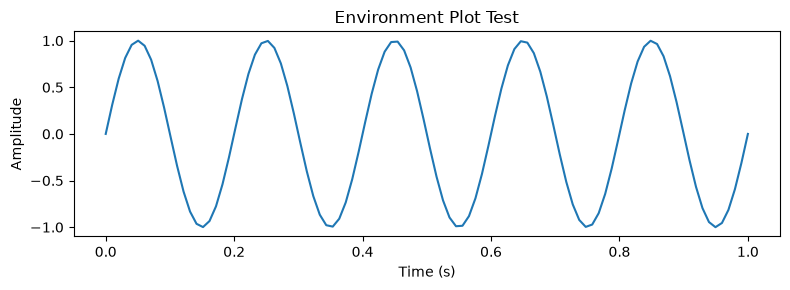

In [15]:
x = np.linspace(
    0,
    1,
    100
)

y = np.sin(
    2 * np.pi * 5 * x
)

plt.figure(
    figsize=(8, 3)
)

plt.plot(
    x,
    y
)

plt.xlabel(
    "Time (s)"
)

plt.ylabel(
    "Amplitude"
)

plt.title(
    "Environment Plot Test"
)

plt.tight_layout()

plt.show()

In [16]:
print(
    "WFDB module available:",
    wfdb is not None
)

WFDB module available: True


In [17]:
checks = {
    "Python executable": Path(
        sys.executable
    ).exists(),

    "Project root": PROJECT_ROOT.exists(),

    "Data folder": DATA_DIR.exists(),

    "Raw data folder": RAW_DATA_DIR.exists(),

    "Processed folder":
        PROCESSED_DATA_DIR.exists(),

    "Results folder":
        RESULTS_DIR.exists(),

    "Figures folder":
        FIGURES_DIR.exists(),

    "TPEHG folder":
        TPEHG_DIR.exists(),

    "TPEHGT folder":
        TPEHGT_DIR.exists(),

    "ICEHG folder":
        ICEHG_DIR.exists(),
}


print("ENVIRONMENT CHECK")
print("=================")

for name, status in checks.items():

    print(
        f"{name:25s}",
        "OK" if status else "FAILED"
    )

ENVIRONMENT CHECK
Python executable         OK
Project root              OK
Data folder               OK
Raw data folder           OK
Processed folder          OK
Results folder            OK
Figures folder            OK
TPEHG folder              OK
TPEHGT folder             OK
ICEHG folder              OK


## Environment Setup Status

Environment configuration completed successfully.

### Verified

- Python virtual environment
- Required Python packages
- Project folder structure
- Dataset directories
- Output directories
- Sampling frequency configuration
- Random seed configuration
- Matplotlib
- WFDB

### Next notebook

`01_dataset_exploration.ipynb`

The next stage will inspect the raw EHG datasets and verify:

- record counts
- signal channels
- metadata
- sampling frequency
- recording duration
- term/preterm labels